# AQR Momentum Strategies

FINM 36700 HW6: AQR Momentum

Group: Avi Rastogi, Lucas Albin Lazcano, Mengting Wang, Siena Verprauskus

## Setup

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:.4f}".format
ANN = 12
FILE = "momentum_data.xlsx"

def load(sheet):
    return pd.read_excel(FILE, sheet_name=sheet, index_col=0, parse_dates=True)

factors = load("factors (excess returns)")    # MKT, SMB, HML (excess)
umd     = load("momentum (excess returns)")["UMD"]
deciles = load("deciles (total returns)")
sizes   = load("size_sorts (total returns)")
rf      = load("risk-free rate")["RF"]

deciles.columns = [f"D{i}" for i in range(1, 11)]   # D1 = losers, D10 = winners
print(f"Sample: {factors.index[0]:%Y-%m} to {factors.index[-1]:%Y-%m}, {len(factors)} months")

Sample: 1927-01 to 2025-08, 1184 months


Helper functions used throughout. Every return series is reported with the same set of statistics, so one function builds the summary table. A shared formatter keeps the tables consistent.

In [2]:
def perf(r, mkt, hml):
    "Annualized summary stats for one monthly excess-return series."
    mkt, hml = mkt.reindex(r.index), hml.reindex(r.index)
    return pd.Series({
        "Mean":        r.mean() * ANN,
        "Vol":         r.std() * np.sqrt(ANN),
        "Sharpe":      r.mean() / r.std() * np.sqrt(ANN),
        "Skewness":    r.skew(),
        "Corr to MKT": r.corr(mkt),
        "Corr to HML": r.corr(hml),
    })

def perf_table(series, start, end):
    "Apply perf() to a dict of series over [start, end]."
    f = factors.loc[start:end]
    return pd.DataFrame({k: perf(v.loc[start:end], f["MKT"], f["HML"]) for k, v in series.items()}).T

FMT = {"Mean": "{:.2%}", "Vol": "{:.2%}", "Sharpe": "{:.2f}", "Skewness": "{:.2f}",
       "Corr to MKT": "{:.2f}", "Corr to HML": "{:.2f}"}

def show(df):
    return df.style.format({k: v for k, v in FMT.items() if k in df.columns})

---
# 2. Investigating Momentum

Data: `momentum_data.xlsx`
- **Tab 1:** momentum factor $\tilde{r}^{\text{mom}}$ and Fama-French momentum $\tilde{r}^{\text{mom:FF}}$
- **Tab 2:** momentum decile portfolios (decile 1 = past losers, decile 10 = past winners)
- **Tab 3:** portfolios sorted on momentum and size: small winners ($r^{\text{momSU}}$), small losers ($r^{\text{momSD}}$), big winners ($r^{\text{momBU}}$), big losers ($r^{\text{momBD}}$)

FF construction:

$$\tilde{r}^{\text{mom:FF}} = \tfrac{1}{2}\left(r^{\text{momBU}} + r^{\text{momSU}}\right) - \tfrac{1}{2}\left(r^{\text{momBD}} + r^{\text{momSD}}\right)$$

**Sanity check.** Before using the provided `UMD` series as $\tilde{r}^{\text{mom:FF}}$, I rebuild it from the size/momentum sorts using the formula above. Because the risk-free rate cancels in a long-short spread, total and excess returns give the same result.

In [3]:
mom_ff_built = (0.5 * (sizes["BIG HiPRIOR"] + sizes["SMALL HiPRIOR"])
                - 0.5 * (sizes["BIG LoPRIOR"] + sizes["SMALL LoPRIOR"]))

print(f"corr(UMD, rebuilt FF momentum) = {umd.corr(mom_ff_built):.6f}")
print(f"mean |difference| = {(umd - mom_ff_built).abs().mean():.2e} per month")

corr(UMD, rebuilt FF momentum) = 1.000000
mean |difference| = 2.86e-05 per month


The two series match almost exactly (the gap is rounding error), so `UMD` is $\tilde{r}^{\text{mom:FF}}$ for the rest of the notebook.

## 2.1 Is momentum still profitable?

Subsamples: 1927–2024, 1927–1993, 1994–2008, 2009–2024.

### (a)
Fill in Table 1 for $\tilde{r}^{\text{mom:FF}}$ across the four subsamples: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$, corr. to $\tilde{r}^{v}$.

In [4]:
periods = {"1927–2024": ("1927", "2024"),
           "1927–1993": ("1927", "1993"),
           "1994–2008": ("1994", "2008"),
           "2009–2024": ("2009", "2024")}

table1 = pd.concat({name: perf_table({"mom:FF": umd}, s, e).iloc[0] for name, (s, e) in periods.items()}, axis=1).T
show(table1)

,Mean,Vol,Sharpe,Skewness,Corr to MKT,Corr to HML
1927–2024,7.39%,16.27%,0.45,-3.07,-0.35,-0.41
1927–1993,8.81%,16.05%,0.55,-3.91,-0.37,-0.50
1994–2008,10.27%,17.54%,0.59,-0.60,-0.24,-0.12
2009–2024,-1.29%,15.80%,-0.08,-2.69,-0.37,-0.32


To show *when* the changes happened, the next plot shows the rolling 5-year Sharpe ratio and the cumulative return.

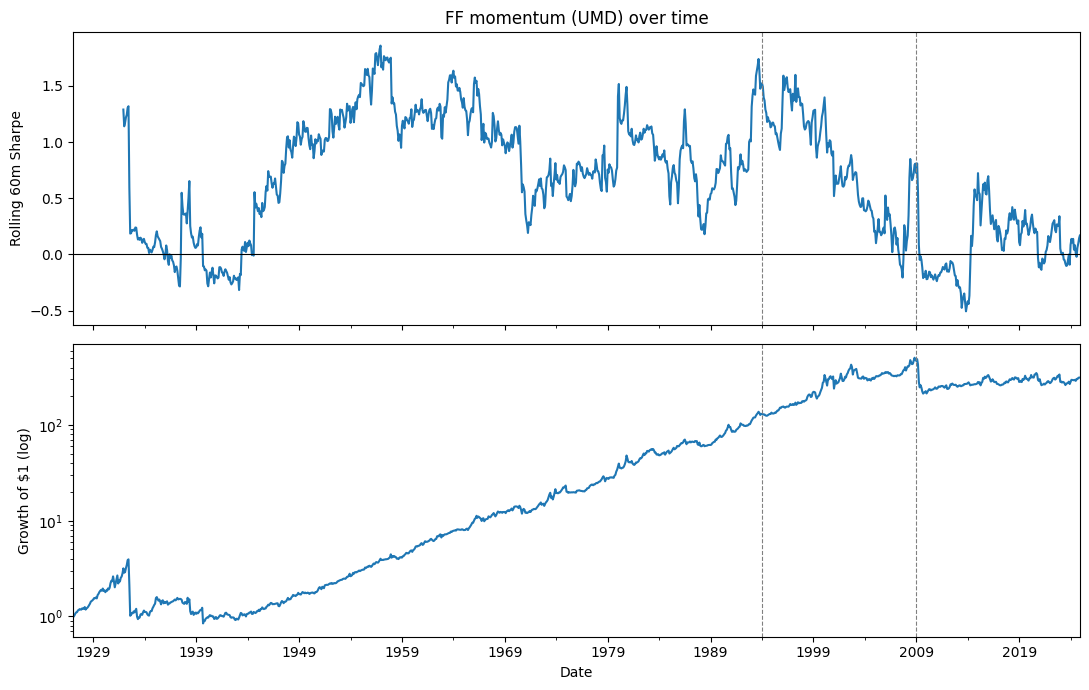

Worst five months:
Date
1932-08-31    -52.6%
1932-07-31    -45.7%
2009-04-30    -34.3%
1939-09-30    -31.4%
2001-01-31    -25.4%


In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

roll = umd.rolling(60)
(roll.mean() / roll.std() * np.sqrt(ANN)).plot(ax=ax1, color="tab:blue")
ax1.axhline(0, color="black", lw=0.8)
ax1.set_ylabel("Rolling 60m Sharpe")
ax1.set_title("FF momentum (UMD) over time")

(1 + umd.loc[:"2024"]).cumprod().plot(ax=ax2, logy=True, color="tab:blue")
ax2.set_ylabel("Growth of $1 (log)")

for ax in (ax1, ax2):
    for yr in ["1994", "2009"]:
        ax.axvline(pd.Timestamp(yr), color="grey", ls="--", lw=0.8)
plt.tight_layout()
plt.show()

print("Worst five months:")
print(umd.nsmallest(5).map("{:.1%}".format).to_string())

### (b)
Has momentum changed much across the subsamples?

**Answer:**

Yes, and the break comes after 2008, not after the strategy was published.

- **1927–1993 (pre-publication):** mean 8.8%, Sharpe 0.55.
- **1994–2008 (just after Jegadeesh & Titman 1993 and Asness 1994):** mean 10.3%, Sharpe 0.59. Publication did *not* arbitrage the premium away. If anything it got slightly stronger, and the crash risk was milder (skew −0.60).
- **2009–2024:** mean −1.3%, Sharpe −0.08. This period starts with the 2009 momentum crash: past losers (beaten-down financials and cyclicals) rebounded sharply when the market recovered, and the short leg was hit hard. The strategy has not recovered its earlier performance since. The rolling Sharpe drifts around zero for most of the period.

The risk profile changed less than the mean. Volatility stays around 16–17%, both correlations stay negative in every subsample, and skewness is strongly negative in all periods except 1994–2008. The worst months (July–August 1932 and April 2009) all came during sharp market rebounds after crashes. So the *risk* of momentum looks stable over time, while its *premium* has been unstable.

### (c)
Does the data support AQR's case that momentum belongs in the ideal portfolio? Would it still be valuable if transaction costs pushed mean returns near zero?

To answer the second part with numbers instead of intuition, I compute the tangency portfolio of MKT, HML and UMD (1927–2024). I do this three ways: with UMD, without UMD, and with UMD's mean set to **zero** while keeping its covariances unchanged (the "transaction costs ate the premium" case).

In [6]:
X = pd.concat([factors[["MKT", "HML"]], umd], axis=1).loc["1927":"2024"]

def tangency(X, mu):
    w = np.linalg.solve(X.cov(), mu)
    w = w / w.sum()
    sharpe = (mu @ w) / np.sqrt(w @ X.cov() @ w) * np.sqrt(ANN)
    return pd.Series(w, index=X.columns), sharpe

cases = {"MKT + HML":              (X[["MKT", "HML"]], X[["MKT", "HML"]].mean()),
         "MKT + HML + UMD":        (X, X.mean()),
         "MKT + HML + UMD (μ=0)":  (X, X.mean().where(X.columns != "UMD", 0.0))}

rows = {}
for name, (data, mu) in cases.items():
    w, sr = tangency(data, mu)
    rows[name] = pd.concat([w, pd.Series({"Tangency Sharpe": sr})])
tan_tbl = pd.DataFrame(rows).T
tan_tbl.style.format("{:.1%}", subset=["MKT", "HML", "UMD"], na_rep="—").format("{:.2f}", subset=["Tangency Sharpe"])

,HML,MKT,Tangency Sharpe,UMD
MKT + HML,48.7%,51.3%,0.50,—
MKT + HML + UMD,33.6%,25.3%,0.94,41.1%
MKT + HML + UMD (μ=0),39.1%,34.9%,0.57,26.0%


**Answer:**

Yes, the data supports AQR's case. Over 1927–2024, FF momentum earns 7.4% a year with a Sharpe of 0.45, and it is *negatively* correlated with both the market (−0.35) and value (−0.41). So it is a positive-premium asset that also hedges the other two main premia. Adding it to MKT + HML raises the tangency Sharpe from about 0.50 to about 0.94, and UMD gets the largest weight (≈41%).

It would still be valuable if costs pushed its mean to roughly zero. Tangency weights are proportional to $\Sigma^{-1}\mu$, not to $\mu$ alone. When UMD's mean is set to zero, the optimizer still puts ≈26% in it, because a zero-mean asset that is negatively correlated with MKT and HML lowers portfolio variance. The tangency Sharpe in that case (≈0.57) is still above the 0.50 without momentum. The diversification benefit alone justifies holding it.

Two caveats:
1. The 2009–2024 period (negative mean) is a reminder that the premium is not guaranteed.
2. The strongly negative skewness (−3.1 full sample) means the Sharpe ratio understates the tail risk. Momentum crashes happen exactly when the market rebounds, so an investor with a short horizon may experience the hedge very differently.

## 2.2 Is a long-only momentum implementation valuable?

Sample: 1994–2024.

Long-only (FF style):

$$\tilde{r}^{\text{momU:FF}} = \tfrac{1}{2}\left(r^{\text{momBU}} + r^{\text{momSU}}\right) - r^f$$

### (a)
Fill in Table 2 comparing long-short $\tilde{r}^{\text{mom:FF}}$ and long-only $\tilde{r}^{\text{momU:FF}}$: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$, corr. to $\tilde{r}^{v}$.

In [7]:
S, E = "1994", "2024"

long_short = umd.loc[S:E]
long_only  = (0.5 * (sizes["BIG HiPRIOR"] + sizes["SMALL HiPRIOR"]) - rf).loc[S:E]   # sizes are total returns → subtract rf
mkt, hml   = factors["MKT"].loc[S:E], factors["HML"].loc[S:E]

table2 = perf_table({"Long-short (mom:FF)": long_short,
                     "Long-only (momU:FF)": long_only,
                     "MKT (reference)":     mkt}, S, E)
show(table2)

,Mean,Vol,Sharpe,Skewness,Corr to MKT,Corr to HML
Long-short (mom:FF),4.31%,16.72%,0.26,-1.46,-0.31,-0.21
Long-only (momU:FF),11.61%,17.80%,0.65,-0.44,0.90,-0.12
MKT (reference),8.98%,15.54%,0.58,-0.60,1.00,-0.09


A Sharpe ratio comparison alone can't tell us how much of the long-only return is momentum and how much is just market exposure. Regressing each series on the market separates the two:

In [8]:
def capm(r):
    fit = sm.OLS(r, sm.add_constant(mkt)).fit()
    return pd.Series({"alpha (ann.)": fit.params["const"] * ANN, "t(alpha)": fit.tvalues["const"],
                      "beta": fit.params["MKT"], "R²": fit.rsquared,
                      "Info. ratio": fit.params["const"] / fit.resid.std() * np.sqrt(ANN)})

capm_tbl = pd.DataFrame({"Long-short (mom:FF)": capm(long_short),
                         "Long-only (momU:FF)": capm(long_only)}).T
capm_tbl.style.format({"alpha (ann.)": "{:.2%}", "t(alpha)": "{:.2f}", "beta": "{:.2f}",
                       "R²": "{:.2f}", "Info. ratio": "{:.2f}"})

,alpha (ann.),t(alpha),beta,R²,Info. ratio
Long-short (mom:FF),7.31%,2.52,-0.33,0.10,0.46
Long-only (momU:FF),2.31%,1.67,1.04,0.82,0.30


### (b)
Is long-only momentum as attractive as long-short on mean, volatility and Sharpe ratio?

**Answer:**

On these three statistics alone, long-only looks *more* attractive: mean 11.6% vs 4.3%, similar volatility (17.8% vs 16.7%), and Sharpe 0.65 vs 0.26. Its skewness is also much less negative (−0.44 vs −1.46), because it avoids the short-loser leg that blows up in rebounds.

The CAPM regression shows why this is misleading. The long-only portfolio has a beta of about 1.04 and an R² of 0.82. Most of its return is the equity premium, which an investor can get cheaply from an index fund. Its alpha over the market is only 2.3% a year (t ≈ 1.7, not significant at 5%). The long-short portfolio's alpha is about three times larger (7.3%, t ≈ 2.5), with a negative beta (−0.33) and an information ratio of 0.46 vs 0.30, because almost none of its return comes from market exposure. In short, the higher Sharpe of long-only comes mostly from the market, not from momentum.

### (c)
Is long-only momentum as diversifying against the market and value premia?

**Answer:**

No. Its correlation with the market is +0.90, compared with −0.31 for long-short. That reverses the hedging property that made momentum attractive in 2.1(c). The correlation with value also weakens from −0.21 to −0.12.

For an investor who already holds the market, adding long-only momentum mostly adds more market risk. The useful part of momentum is the spread between winners and losers. The long-only version keeps only a small piece of that spread (the 2.3% alpha), packaged with a full unit of beta.

### (d)
Plot the cumulative product of $(1+\tilde{r}^{\text{mom:FF}})$ and $(1+\tilde{r}^{\text{momU:FF}})$ over 1994–2024.

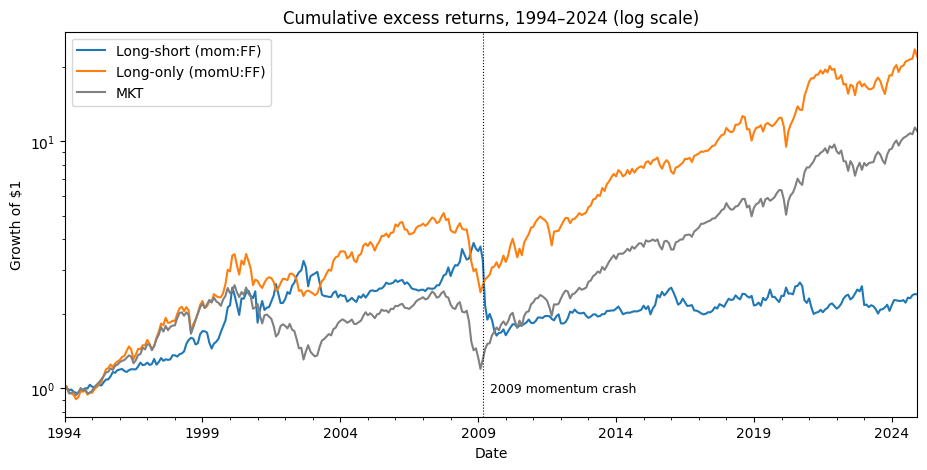

In [9]:
cum = pd.DataFrame({"Long-short (mom:FF)": long_short,
                    "Long-only (momU:FF)": long_only,
                    "MKT":                 mkt}).add(1).cumprod()

ax = cum.plot(logy=True, figsize=(11, 5), color=["tab:blue", "tab:orange", "grey"],
              title="Cumulative excess returns, 1994–2024 (log scale)")
ax.set_ylabel("Growth of $1")
ax.axvline(pd.Timestamp("2009-03"), color="black", ls=":", lw=0.8)
ax.annotate("2009 momentum crash", xy=(pd.Timestamp("2009-03"), cum.min().min()), xytext=(5, 5),
            textcoords="offset points", fontsize=9)
plt.show()

The plot confirms the tables. Long-only moves almost exactly with the market, just slightly above it. Long-short follows a separate path: strong until 2008, a sharp drop in 2009, and roughly flat afterwards.

## 2.3 Is momentum data mining or a robust strategy?

Sample: 1994–2024. Long-short constructions, equal-weighted across included deciles:
- $\tilde{r}^{\text{momD1}}$: top 1 decile minus bottom 1 decile
- $\tilde{r}^{\text{momD3}}$: top 3 deciles minus bottom 3 deciles
- $\tilde{r}^{\text{momD5}}$: top 5 deciles minus bottom 5 deciles

### (a)
Fill in Table 3 for $\tilde{r}^{\text{momD1}}$, $\tilde{r}^{\text{momD3}}$, $\tilde{r}^{\text{momD5}}$: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$, corr. to $\tilde{r}^{v}$.

In [10]:
d = deciles.loc[S:E]

def top_minus_bottom(k):
    "Equal-weight top k deciles minus equal-weight bottom k deciles."
    return d.iloc[:, -k:].mean(axis=1) - d.iloc[:, :k].mean(axis=1)

mom_d = {f"momD{k}": top_minus_bottom(k) for k in (1, 3, 5)}

table3 = perf_table({**mom_d, "mom:FF (ref.)": long_short}, S, E)
show(table3)

,Mean,Vol,Sharpe,Skewness,Corr to MKT,Corr to HML
momD1,8.10%,29.96%,0.27,-1.30,-0.32,-0.24
momD3,2.97%,19.37%,0.15,-1.34,-0.36,-0.21
momD5,1.73%,13.43%,0.13,-1.42,-0.35,-0.21
mom:FF (ref.),4.31%,16.72%,0.26,-1.46,-0.31,-0.21


A further robustness check: if momentum were a data-mining artifact, average returns would not need to line up with past performance across the deciles. A real effect should show returns rising steadily from D1 to D10.

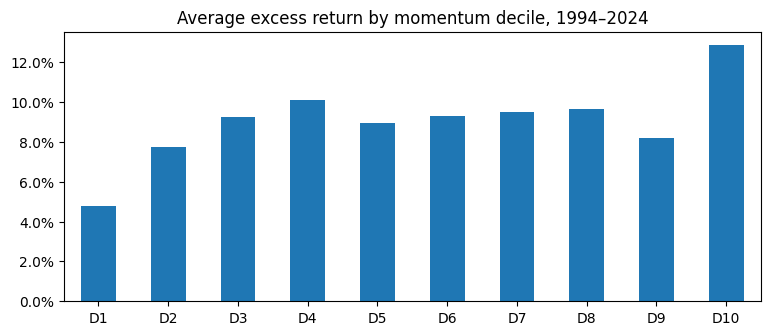

In [11]:
dec_mean = (d.sub(rf.loc[S:E], axis=0)).mean() * ANN
ax = dec_mean.plot.bar(figsize=(9, 3.5), color="tab:blue", title="Average excess return by momentum decile, 1994–2024")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.xticks(rotation=0)
plt.show()

### (b)
Do the tradeoffs across the 1-, 3- and 5-decile constructions match the theory from lecture?

**Answer:**

Yes. A more selective sort pushes the two legs further apart in past performance, so the spread earns a higher mean. Each leg also holds fewer stocks, so it is less diversified and more volatile.

| | Mean | Vol | Sharpe |
|---|---|---|---|
| momD1 | 8.1% | 30.0% | 0.27 |
| momD3 | 3.0% | 19.4% | 0.15 |
| momD5 | 1.7% | 13.4% | 0.13 |

Mean and volatility both fall steadily as the sort widens. In this sample the mean falls faster than the volatility, so the Sharpe also falls. Correlations with MKT (≈ −0.33 to −0.36) and HML (≈ −0.21 to −0.24) hardly change, so the hedging property does not depend on the cutoff.

The bar chart supports the same conclusion. Average excess returns rise from the loser deciles to the winner deciles, and most of the spread comes from the extremes (D1 is very weak, D10 is strong). A smooth, monotone pattern that does not depend on a particular cutoff is what a real effect looks like. It is hard to explain as data mining, which would usually show up as a result that only works for one specific construction.

### (c)
Should AQR's retail product use a 1-decile or a 5-decile construction?

**Answer:**

In this data the 1-decile spread has the best Sharpe (0.27 vs 0.13), with essentially the same diversification against MKT and HML. On paper, then, the most selective construction is best. For a *retail* product, though, I would choose something closer to the broader end (3 deciles, as AQR actually does), for three reasons:

1. **Trading costs.** The extreme deciles have the highest turnover, since stocks move in and out of the top and bottom 10% often. They also tend to hold smaller, less liquid names. The Sharpe gap here is before costs, and costs fall most heavily on momD1.
2. **Volatility and tail risk.** momD1 has 30% volatility and a worst month of about −45%. Retail investors tend to sell after drawdowns, so a product they will actually hold is worth more than a slightly higher Sharpe on paper.
3. **Capacity.** A retail fund that grows needs a broad, liquid universe. 10% of stocks is a narrow base.

The 5-decile version goes too far in the other direction: its mean of 1.7% is small enough that modest costs would eliminate it. A 3-decile construction is a reasonable middle ground.

### (d)
Compare $\tilde{r}^{\text{momD3}}$ with the FF construction in Table 2. Both are 3-decile long-short, but FF separates small and large stocks.

**Answer:**

FF momentum has a higher mean (4.3% vs 3.0%), lower volatility (16.7% vs 19.4%) and therefore a much higher Sharpe (0.26 vs 0.15). Correlations with MKT and HML are almost identical, and skewness is similar (−1.46 vs −1.34).

The difference comes from the size split. The decile portfolios are value-weighted across all stocks, so momD3 is dominated by mega-caps. FF builds the winner and loser legs *within* small and big stocks separately and then gives each half equal weight. This has two effects:
- Small stocks get 50% of the weight, and momentum is much stronger among small stocks (see 2.4). That raises the mean.
- Combining two partly independent spreads (small and big) diversifies, and controlling for size removes a source of noise. That lowers the volatility.

## 2.4 Does implementation require trading many small stocks?

Sample: 1994–2024.
- Small-stock momentum: $r^{\text{momS}} = r^{\text{momSU}} - r^{\text{momSD}}$
- Big-stock momentum: $r^{\text{momB}} = r^{\text{momBU}} - r^{\text{momBD}}$

### (a)
Fill in Table 4 for all stocks, small stocks and large stocks: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$.

In [12]:
z = sizes.loc[S:E]
mom_small = z["SMALL HiPRIOR"] - z["SMALL LoPRIOR"]
mom_big   = z["BIG HiPRIOR"]   - z["BIG LoPRIOR"]

table4 = perf_table({"All stocks (mom:FF)": long_short,
                     "Small stocks (momS)": mom_small,
                     "Large stocks (momB)": mom_big}, S, E).drop(columns="Corr to HML")
show(table4)

,Mean,Vol,Sharpe,Skewness,Corr to MKT
All stocks (mom:FF),4.31%,16.72%,0.26,-1.46,-0.31
Small stocks (momS),6.14%,16.91%,0.36,-1.80,-0.31
Large stocks (momB),2.46%,18.23%,0.14,-0.87,-0.28


In [13]:
print(f"corr(momS, momB) = {mom_small.corr(mom_big):.2f}")
print(f"Share of mom:FF mean coming from the small leg: {0.5*mom_small.mean() / long_short.mean():.0%}")

corr(momS, momB) = 0.81
Share of mom:FF mean coming from the small leg: 71%


### (b)
Is momentum's attractiveness driven mostly by small stocks, or does large-stock momentum still offer comparable risk-adjusted excess returns?

**Answer:**

Mostly by small stocks. Small-stock momentum earns 6.1% a year with a Sharpe of 0.36. Large-stock momentum earns 2.5% with a Sharpe of 0.14. Volatility is similar (16.9% vs 18.2%), so the gap comes from returns, not risk. About 71% of the FF momentum mean comes from the small-stock half.

Large-stock momentum is therefore not comparable on risk-adjusted terms, though it is not worthless. It still has a positive mean, a similar negative correlation with the market (−0.28), and noticeably less crash risk (skew −0.87 vs −1.80). The two spreads are highly but not perfectly correlated (0.81), so combining them gives the lower FF volatility seen in 2.3(d).

The catch is that small-stock momentum is the part that is most expensive to trade: low liquidity, wide spreads and high turnover. Some of its 3.7-point advantage would be lost to costs in practice. Large-cap momentum has a much smaller premium on paper, but more of it survives costs.

## 2.5 Conclusion

Assess the AQR retail product. Does it capture the key features of the FF momentum construction? What modifications would you suggest?

**Answer:**

The AQR retail product is long-only, holds roughly the top third of large/mid-cap stocks by momentum, is value-weighted, and rebalances quarterly. It captures the *signal* of FF momentum but not its *portfolio properties*.

**What it captures.** The winner sort itself is robust. Returns rise steadily across the deciles (2.3), so a top-third portfolio does tilt toward the momentum premium. Long-only momentum has also beaten the market slightly (≈2.3%/yr CAPM alpha in 1994–2024).

**What it misses.**
1. **The hedge.** Without the short leg, correlation with the market goes from −0.31 to +0.90 (2.2). Momentum's value in an optimal portfolio comes mostly from its negative correlation with MKT and HML. 2.1(c) showed that even a zero-mean long-short momentum earns a 26% tangency weight. The long-only product loses most of this and acts as roughly 1.0× market beta plus a small tilt.
2. **The small-cap premium.** Value-weighting and a large/mid-cap universe exclude the part of the market where momentum is strongest (Sharpe 0.36 small vs 0.14 large, 2.4).

**What it does well.** Quarterly rebalancing and a broad top-third cutoff greatly reduce turnover and trading costs. These costs are not reflected in the FF paper returns, so the paper-return gap overstates how much better FF would do in practice.

**Suggested modifications.**
- **Add a limited short leg** (e.g. a 130/30 structure, or a separate long-short sleeve). Even a partial short in losers brings back some of the negative market correlation, which is the main reason to own momentum.
- **Neutralize size inside the sort.** Rank winners within size buckets, as FF does, and tilt toward mid/smaller caps as far as liquidity allows (e.g. equal-weight or capped weights instead of pure value-weighting). This captures more of the stronger small-cap momentum without going into micro-caps.
- **Market it as a complement, not a replacement.** As long as it stays long-only, the product should be presented as a market tilt with modest alpha, not as a diversifier.
- **Consider crash management.** The worst momentum losses happen in sharp rebounds after bear markets (1932, 2009). Volatility-scaling the position, i.e. reducing exposure when recent momentum volatility is high, would reduce the strategy's worst tail risk.

## Acknowledgement

I used Claude (Anthropic) to help write and organize the code and to review my written answers. All numbers quoted in the answers come from the outputs of this notebook.